### РОССИЙСКИЙ УНИВЕРСИТЕТ ДРУЖБЫ НАРОДОВ
### Факультет искусственного интеллекта
### Дисциплина: Инструменты обработки и визуализации данных
## ОТЧЕТ ПО ЛАБОРАТОРНОЙ РАБОТЕ № 5
#### Студент:  Князев Арсений Михайлович
#### Группа:   ЗФИбд-01-24
#### Вариант № 1

### Цель работы

Подготовить данные Adult и сравнить четыре модели регрессии для прогноза количества рабочих часов в неделю.

In [1]:
import os
import sys

from pyspark.sql import SparkSession

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")

spark = (
    SparkSession.builder.master("local[*]")
    .appName("AdultRegressionLab5")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

print("spark:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/09 17:09:31 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


spark: 4.0.1


### Загрузка и очистка

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.feature import OneHotEncoder, StringIndexer, VectorAssembler
from pyspark.ml.regression import (
    DecisionTreeRegressor,
    GBTRegressor,
    LinearRegression,
    RandomForestRegressor,
)
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, IntegerType, StringType, StructField, StructType

sns.set_theme(style="whitegrid")

DATA_FILE = "adult.data"

schema = StructType(
    [
        StructField("age", IntegerType(), True),
        StructField("workclass", StringType(), True),
        StructField("fnlwgt", DoubleType(), True),
        StructField("education", StringType(), True),
        StructField("education_num", IntegerType(), True),
        StructField("marital_status", StringType(), True),
        StructField("occupation", StringType(), True),
        StructField("relationship", StringType(), True),
        StructField("race", StringType(), True),
        StructField("sex", StringType(), True),
        StructField("capital_gain", DoubleType(), True),
        StructField("capital_loss", DoubleType(), True),
        StructField("hours_per_week", DoubleType(), True),
        StructField("native_country", StringType(), True),
        StructField("income", StringType(), True),
    ]
)

df_raw = (
    spark.read.option("header", False)
    .option("nullValue", "?")
    .option("ignoreLeadingWhiteSpace", True)
    .option("ignoreTrailingWhiteSpace", True)
    .schema(schema)
    .csv(DATA_FILE)
)

df = df_raw.dropna().dropDuplicates().withColumn("label", F.col("hours_per_week"))

print("исходная форма:", (df_raw.count(), len(df_raw.columns)))
print("после очистки:", (df.count(), len(df.columns)))
df.printSchema()
print(df.dtypes)
df.show(5, truncate=False)

исходная форма: (32561, 15)


после очистки: (30139, 16)
root
 |-- age: integer (nullable = true)
 |-- workclass: string (nullable = true)
 |-- fnlwgt: double (nullable = true)
 |-- education: string (nullable = true)
 |-- education_num: integer (nullable = true)
 |-- marital_status: string (nullable = true)
 |-- occupation: string (nullable = true)
 |-- relationship: string (nullable = true)
 |-- race: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- capital_gain: double (nullable = true)
 |-- capital_loss: double (nullable = true)
 |-- hours_per_week: double (nullable = true)
 |-- native_country: string (nullable = true)
 |-- income: string (nullable = true)
 |-- label: double (nullable = true)

[('age', 'int'), ('workclass', 'string'), ('fnlwgt', 'double'), ('education', 'string'), ('education_num', 'int'), ('marital_status', 'string'), ('occupation', 'string'), ('relationship', 'string'), ('race', 'string'), ('sex', 'string'), ('capital_gain', 'double'), ('capital_loss', 'double'), ('hours_per_w

+---+---------+--------+------------+-------------+---------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+-----+
|age|workclass|fnlwgt  |education   |education_num|marital_status       |occupation       |relationship |race |sex   |capital_gain|capital_loss|hours_per_week|native_country|income|label|
+---+---------+--------+------------+-------------+---------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+-----+
|42 |Private  |116632.0|Doctorate   |16           |Married-civ-spouse   |Prof-specialty   |Husband      |White|Male  |0.0         |0.0         |45.0          |United-States |>50K  |45.0 |
|44 |Private  |343591.0|HS-grad     |9            |Divorced             |Craft-repair     |Not-in-family|White|Female|14344.0     |0.0         |40.0          |United-States |>50K  |40.0 |
|46 |Local-gov|329752.0|11th        |7            |Married-c

In [3]:
numeric_columns = [
    "age",
    "fnlwgt",
    "education_num",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
]

df.select(numeric_columns).summary().show(truncate=False)

+-------+-----------------+------------------+------------------+------------------+-----------------+------------------+
|summary|age              |fnlwgt            |education_num     |capital_gain      |capital_loss     |hours_per_week    |
+-------+-----------------+------------------+------------------+------------------+-----------------+------------------+
|count  |30139            |30139             |30139             |30139             |30139            |30139             |
|mean   |38.44172003052523|189795.02597962774|10.122532267162148|1092.8412024287468|88.43992833206144|40.934702544875414|
|stddev |13.13142597131538|105658.6243405509 |2.548738452612677 |7409.11059631244  |404.4452387625342|11.978753137561938|
|min    |17               |13769.0           |1                 |0.0               |0.0              |1.0               |
|25%    |28               |117618.0          |9                 |0.0               |0.0              |40.0              |
|50%    |37             

### Подготовка признаков

In [4]:
numeric_features = [
    "age",
    "fnlwgt",
    "education_num",
    "capital_gain",
    "capital_loss",
]
categorical_features = [
    "workclass",
    "education",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "native_country",
    "income",
]

train_raw, test_raw = df.randomSplit([0.8, 0.2], seed=42)
train_raw = train_raw.cache()
test_raw = test_raw.cache()

print("train:", train_raw.count())
print("test:", test_raw.count())

train: 24026


test: 6113


In [5]:
indexers = [
    StringIndexer(
        inputCol=column,
        outputCol=f"{column}_index",
        handleInvalid="keep",
    )
    for column in categorical_features
]

encoders = [
    OneHotEncoder(
        inputCol=f"{column}_index",
        outputCol=f"{column}_ohe",
        handleInvalid="keep",
    )
    for column in categorical_features
]

encoded_columns = [f"{column}_ohe" for column in categorical_features]
assembler = VectorAssembler(
    inputCols=numeric_features + encoded_columns,
    outputCol="features",
)

feature_pipeline = Pipeline(stages=indexers + encoders + [assembler])
feature_model = feature_pipeline.fit(train_raw)

train_data = feature_model.transform(train_raw).cache()
test_data = feature_model.transform(test_raw).cache()

train_data.select("features", "label", "income").show(5, truncate=False)

+---------------------------------------------------------------------------------------------------------+-----+------+
|features                                                                                                 |label|income|
+---------------------------------------------------------------------------------------------------------+-----+------+
|(113,[0,1,2,3,5,20,31,43,55,63,67,69,110],[17.0,130125.0,6.0,1055.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])|20.0 |<=50K |
|(113,[0,1,2,5,18,31,38,55,60,67,69,110],[17.0,173807.0,7.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])         |15.0 |<=50K |
|(113,[0,1,2,5,18,31,43,55,60,67,69,110],[18.0,182042.0,7.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])         |19.0 |<=50K |
|(113,[0,1,2,5,13,31,38,58,60,66,69,110],[19.0,256979.0,9.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])         |35.0 |<=50K |
|(113,[0,1,2,5,14,31,43,55,60,66,69,110],[19.0,320014.0,10.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0])        |25.0 |<=50K |
+-------------------------------

### Обучение моделей

In [6]:
estimators = {
    "LinearRegression": LinearRegression(
        featuresCol="features", labelCol="label", maxIter=80, regParam=0.05
    ),
    "DecisionTree": DecisionTreeRegressor(
        featuresCol="features", labelCol="label", maxDepth=7, minInstancesPerNode=10, seed=42
    ),
    "RandomForest": RandomForestRegressor(
        featuresCol="features", labelCol="label", numTrees=30, maxDepth=7, seed=42
    ),
    "GBT": GBTRegressor(
        featuresCol="features", labelCol="label", maxIter=25, maxDepth=4, stepSize=0.1, seed=42
    ),
}

rmse_evaluator = RegressionEvaluator(
    labelCol="label", predictionCol="prediction", metricName="rmse"
)
r2_evaluator = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2")

fitted_models = {}
predictions = {}
metrics_rows = []

for name, estimator in estimators.items():
    model = estimator.fit(train_data)
    train_predictions = model.transform(train_data)
    test_predictions = model.transform(test_data).cache()

    fitted_models[name] = model
    predictions[name] = test_predictions
    metrics_rows.append(
        {
            "model": name,
            "train_rmse": rmse_evaluator.evaluate(train_predictions),
            "test_rmse": rmse_evaluator.evaluate(test_predictions),
            "train_r2": r2_evaluator.evaluate(train_predictions),
            "test_r2": r2_evaluator.evaluate(test_predictions),
        }
    )

metrics_pdf = pd.DataFrame(metrics_rows).sort_values("test_r2", ascending=False)
metrics_pdf.round(4)

,model,train_rmse,test_rmse,train_r2,test_r2
2,RandomForest,10.2028,10.3680,0.2763,0.2434
3,GBT,10.1614,10.3714,0.2822,0.2429
1,DecisionTree,10.3650,10.5330,0.2531,0.2191
0,LinearRegression,10.7444,10.7515,0.1974,0.1864


### Сравнение

In [7]:
best_name = metrics_pdf.iloc[0]["model"]
best_row = metrics_pdf.iloc[0]

tree_names = ["DecisionTree", "RandomForest", "GBT"]
best_tree_name = max(
    tree_names,
    key=lambda name: metrics_pdf.set_index("model").loc[name, "test_r2"],
)
best_tree_model = fitted_models[best_tree_name]

numeric_importance = dict(
    zip(
        numeric_features,
        best_tree_model.featureImportances.toArray()[: len(numeric_features)],
    )
)
key_feature = max(numeric_importance, key=numeric_importance.get)

print("лучшая модель:", best_name)
print("test RMSE:", round(best_row["test_rmse"], 4))
print("test R2:", round(best_row["test_r2"], 4))
print("лучшая древесная модель:", best_tree_name)
print("важность числовых признаков:", {k: round(v, 4) for k, v in numeric_importance.items()})
print("ключевой числовой признак:", key_feature)

r2_gap = best_row["train_r2"] - best_row["test_r2"]
if best_row["test_r2"] < 0.2:
    print("вывод: модели объясняют небольшую часть разброса, заметно недообучение")
elif r2_gap > 0.1:
    print("вывод: разрыв между train и test указывает на переобучение")
else:
    print("вывод: сильного переобучения не видно")

лучшая модель: RandomForest
test RMSE: 10.368
test R2: 0.2434
лучшая древесная модель: RandomForest
важность числовых признаков: {'age': np.float64(0.3741), 'fnlwgt': np.float64(0.0171), 'education_num': np.float64(0.0322), 'capital_gain': np.float64(0.0034), 'capital_loss': np.float64(0.0016)}
ключевой числовой признак: age
вывод: сильного переобучения не видно


### Фактические значения

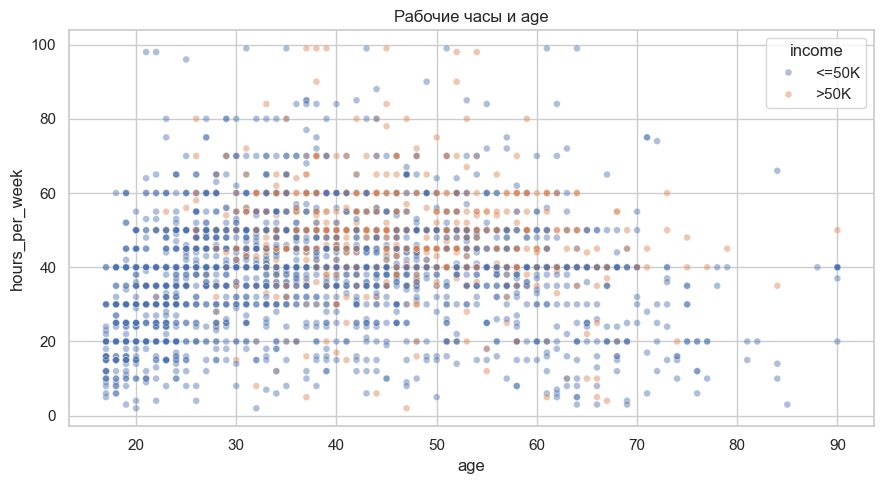

In [8]:
scatter_pdf = (
    df.select(key_feature, "hours_per_week", "income")
    .sample(withReplacement=False, fraction=0.18, seed=42)
    .limit(5000)
    .toPandas()
)

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=scatter_pdf,
    x=key_feature,
    y="hours_per_week",
    hue="income",
    alpha=0.45,
    s=24,
)
plt.title(f"Рабочие часы и {key_feature}")
plt.ylabel("hours_per_week")
plt.tight_layout()
plt.show()

### Предсказания моделей

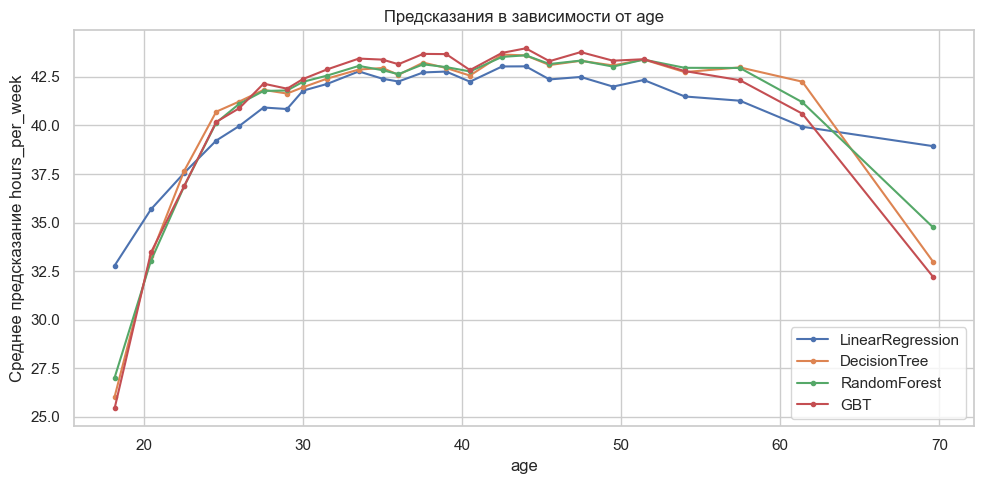

In [9]:
plt.figure(figsize=(10, 5))

for name, prediction_df in predictions.items():
    plot_pdf = prediction_df.select(key_feature, "prediction").toPandas()
    plot_pdf["bin"] = pd.qcut(plot_pdf[key_feature], q=25, duplicates="drop")
    curve = (
        plot_pdf.groupby("bin", observed=True)
        .agg(x=(key_feature, "mean"), prediction=("prediction", "mean"))
        .sort_values("x")
    )
    plt.plot(curve["x"], curve["prediction"], marker="o", markersize=3, label=name)

plt.title(f"Предсказания в зависимости от {key_feature}")
plt.xlabel(key_feature)
plt.ylabel("Среднее предсказание hours_per_week")
plt.legend()
plt.tight_layout()
plt.show()

### Кривая обучения

In [10]:
curve_train_raw, curve_validation_raw = train_raw.randomSplit([0.8, 0.2], seed=42)
curve_train_raw = curve_train_raw.cache()
curve_validation_raw = curve_validation_raw.cache()

fractions = [0.2, 0.4, 0.6, 0.8, 1.0]
learning_rows = []

for fraction in fractions:
    subset_raw = curve_train_raw.sample(
        withReplacement=False,
        fraction=fraction,
        seed=42,
    ).cache()
    subset_count = subset_raw.count()

    curve_feature_model = feature_pipeline.fit(subset_raw)
    subset = curve_feature_model.transform(subset_raw).cache()
    curve_validation = curve_feature_model.transform(curve_validation_raw)
    curve_model = estimators[best_tree_name].copy({}).fit(subset)
    train_r2 = r2_evaluator.evaluate(curve_model.transform(subset))
    validation_r2 = r2_evaluator.evaluate(curve_model.transform(curve_validation))

    learning_rows.append(
        {
            "fraction": fraction,
            "rows": subset_count,
            "train_r2": train_r2,
            "validation_r2": validation_r2,
        }
    )
    subset.unpersist()
    subset_raw.unpersist()

learning_pdf = pd.DataFrame(learning_rows)
learning_pdf.round(4)

,fraction,rows,train_r2,validation_r2
0,0.2,3903,0.3580,0.2171
1,0.4,7745,0.3245,0.2307
2,0.6,11494,0.3104,0.2286
3,0.8,15352,0.2903,0.2284
4,1.0,19185,0.2816,0.2322


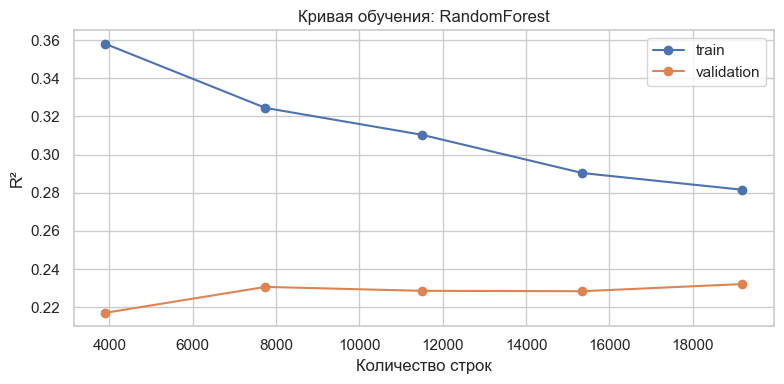

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(learning_pdf["rows"], learning_pdf["train_r2"], marker="o", label="train")
plt.plot(
    learning_pdf["rows"],
    learning_pdf["validation_r2"],
    marker="o",
    label="validation",
)
plt.title(f"Кривая обучения: {best_tree_name}")
plt.xlabel("Количество строк")
plt.ylabel("R²")
plt.legend()
plt.tight_layout()
plt.show()

### Вывод

Лучший результат показал Random Forest: RMSE = 10.3680, R² = 0.2434 на тестовой выборке. На обучающей выборке R² = 0.2763, поэтому сильного переобучения нет. Невысокий R² и плато валидационной кривой около 0.23 говорят, что модель недообучена и выбранные признаки объясняют только часть разброса рабочих часов. Самым важным числовым признаком оказался возраст (`age`).